# Model Training and Risk Score
Employee Attrition Risk Analyzer

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold, cross_val_predict
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, ConfusionMatrixDisplay, RocCurveDisplay)

sns.set_theme(style="whitegrid")

data = pd.read_csv("../data/processed/model_ready_data.csv")
X = data.drop(columns=["Attrition"])
y = data["Attrition"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42)

print("Train:", X_train.shape, "Test:", X_test.shape)
print("Attrition in train: {:.1f}% | test: {:.1f}%".format(y_train.mean()*100, y_test.mean()*100))

Train: (1176, 44) Test: (294, 44)
Attrition in train: 16.2% | test: 16.0%


In [2]:
neg, pos = (y_train == 0).sum(), (y_train == 1).sum()

models = {
    "Logistic Regression": Pipeline([
        ("scaler", StandardScaler()),
        ("clf", LogisticRegression(max_iter=2000, class_weight="balanced", random_state=42))
    ]),
    "Random Forest": RandomForestClassifier(
        n_estimators=300, class_weight="balanced", random_state=42, n_jobs=-1),
    "XGBoost": XGBClassifier(
        n_estimators=300, learning_rate=0.05, max_depth=4,
        scale_pos_weight=neg/pos, eval_metric="logloss", random_state=42),
}

for name, m in models.items():
    m.fit(X_train, y_train)
    print("Trained:", name)

Trained: Logistic Regression
Trained: Random Forest
Trained: XGBoost


In [3]:
param_grid = {
    "n_estimators": [200, 400],
    "max_depth": [5, 10, None],
    "min_samples_leaf": [1, 3, 5],
}

grid = GridSearchCV(
    RandomForestClassifier(class_weight="balanced", random_state=42, n_jobs=-1),
    param_grid, cv=5, scoring="roc_auc", n_jobs=-1)
grid.fit(X_train, y_train)

print("Best params:", grid.best_params_)
print("Best CV ROC-AUC: {:.3f}".format(grid.best_score_))
models["Random Forest (Tuned)"] = grid.best_estimator_

Best params: {'max_depth': 10, 'min_samples_leaf': 5, 'n_estimators': 200}
Best CV ROC-AUC: 0.795


In [4]:
rows = []
for name, m in models.items():
    pred = m.predict(X_test)
    prob = m.predict_proba(X_test)[:, 1]
    rows.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, pred),
        "Precision": precision_score(y_test, pred),
        "Recall": recall_score(y_test, pred),
        "F1": f1_score(y_test, pred),
        "ROC-AUC": roc_auc_score(y_test, prob),
    })

results = pd.DataFrame(rows).set_index("Model").round(3)
results.to_csv("../outputs/tables/model_comparison.csv")
results

,Accuracy,Precision,Recall,F1,ROC-AUC
Model,,,,,
Logistic Regression,0.752,0.345,0.617,0.443,0.798
Random Forest,0.833,0.462,0.255,0.329,0.787
XGBoost,0.830,0.462,0.383,0.419,0.771
Random Forest (Tuned),0.820,0.448,0.553,0.495,0.780


In [5]:
best_name = results["ROC-AUC"].idxmax()
best_model = models[best_name]
print("Best model (by ROC-AUC):", best_name)
print(results.loc[best_name])

Best model (by ROC-AUC): Logistic Regression
Accuracy     0.752
Precision    0.345
Recall       0.617
F1           0.443
ROC-AUC      0.798
Name: Logistic Regression, dtype: float64


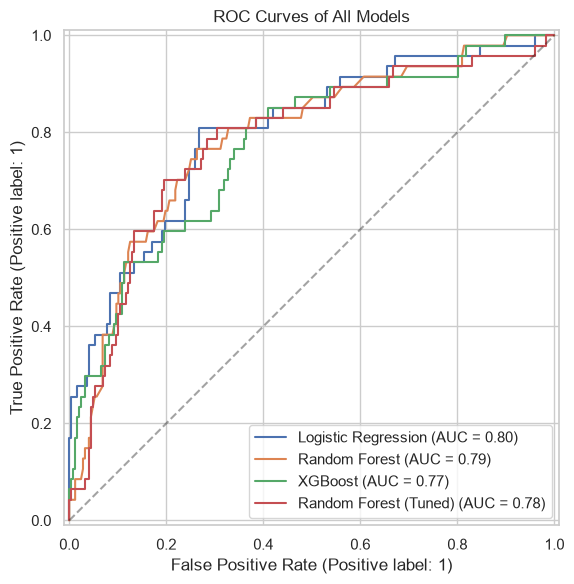

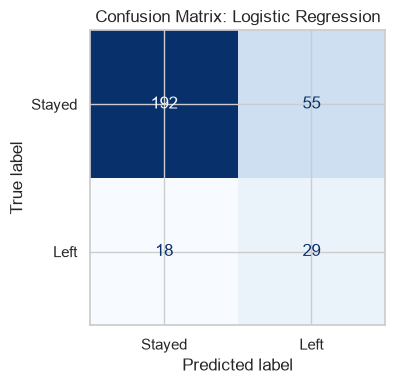

In [6]:
fig, ax = plt.subplots(figsize=(7, 6))
for name, m in models.items():
    RocCurveDisplay.from_estimator(m, X_test, y_test, ax=ax, name=name)
ax.plot([0, 1], [0, 1], "k--", alpha=0.4)
ax.set_title("ROC Curves of All Models")
plt.tight_layout()
plt.savefig("../outputs/charts/04_roc_curves.png", dpi=300)
plt.show()

fig, ax = plt.subplots(figsize=(5, 4))
ConfusionMatrixDisplay.from_estimator(best_model, X_test, y_test, ax=ax, cmap="Blues",
                                      display_labels=["Stayed", "Left"], colorbar=False)
ax.set_title(f"Confusion Matrix: {best_name}")
plt.tight_layout()
plt.savefig("../outputs/charts/04_confusion_matrix.png", dpi=300)
plt.show()

In [7]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
oof_prob = cross_val_predict(best_model, X, y, cv=cv, method="predict_proba")[:, 1]

clean = pd.read_csv("../data/processed/cleaned_data.csv")
risk = clean[["EmployeeNumber", "Department", "JobRole", "Attrition"]].copy()
risk["RiskScore"] = (oof_prob * 100).round(1)
risk["RiskLevel"] = pd.cut(risk["RiskScore"], [-1, 30, 60, 100],
                           labels=["Low", "Medium", "High"])

print(risk["RiskLevel"].value_counts())
print("\nActual attrition rate by risk level (%):")
print(risk.groupby("RiskLevel", observed=True)["Attrition"]
          .apply(lambda s: (s == "Yes").mean() * 100).round(1))
risk.head()

RiskLevel
Low       760
High      358
Medium    352
Name: count, dtype: int64

Actual attrition rate by risk level (%):
RiskLevel
Low        3.9
Medium    16.2
High      41.9
Name: Attrition, dtype: float64


,EmployeeNumber,Department,JobRole,Attrition,RiskScore,RiskLevel
0,1,Sales,Sales Executive,Yes,90.6,High
1,2,Research & Development,Research Scientist,No,10.7,Low
2,4,Research & Development,Laboratory Technician,Yes,85.1,High
3,5,Research & Development,Research Scientist,No,52.8,Medium
4,7,Research & Development,Laboratory Technician,No,60.1,High


In [8]:
risk.to_csv("../data/processed/risk_scores.csv", index=False)
joblib.dump(best_model, "../models/best_model.pkl")
joblib.dump(models["Random Forest (Tuned)"], "../models/random_forest_tuned.pkl")
joblib.dump(list(X.columns), "../models/feature_columns.pkl")
print("Saved.")

Saved.
